# 06 - Feature Set Ablation
Train the same models on a few different feature sets and compare out-of-sample IC side by side — e.g. with vs. without the day-of-week/session-time (calendar) features, or a minimal price-only set vs. the full set.

Edit `FEATURE_SETS` below to try your own combinations.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import fetch_ohlcv
from src.target import ForwardLogReturnTarget
from src.dataset import build_dataset, ChronologicalSplitter, CausalScaler
from src.models import RidgeModel, XGBoostModel
from src.metrics import pearson_ic, spearman_ic, hit_rate
from src.progress import NotebookProgress, XGBProgressCallback
from src.features import (
    FeatureEngine,
    LogReturnFeature, RollingZScoreFeature, RangePositionFeature,
    RealizedVolatilityFeature, RelativeVolumeFeature, SignedVolumeFlowFeature,
    SessionTimeSinFeature, SessionTimeCosFeature, DayOfWeekSinFeature, DayOfWeekCosFeature,
)

## 1. Fetch data once (shared across all feature sets)

In [2]:
TICKER, INTERVAL, PERIOD = 'SPY', '5m', '60d'
df = fetch_ohlcv(TICKER, INTERVAL, PERIOD)
df.shape

(4661, 5)

## 2. Define the feature sets to compare
Each is just a list of `Feature` instances — same building blocks as notebook 01.

In [3]:
def price_action_features():
    return [
        LogReturnFeature(horizon=1), LogReturnFeature(horizon=5), LogReturnFeature(horizon=15),
        RollingZScoreFeature(window=30), RangePositionFeature(window=30),
        RealizedVolatilityFeature(window=30),
    ]

def volume_features():
    return [RelativeVolumeFeature(window=30), SignedVolumeFlowFeature()]

def calendar_features():
    return [SessionTimeSinFeature(), SessionTimeCosFeature(), DayOfWeekSinFeature(), DayOfWeekCosFeature()]


FEATURE_SETS = {
    'minimal_price_only': price_action_features(),
    'no_calendar': price_action_features() + volume_features(),
    'full': price_action_features() + volume_features() + calendar_features(),
}

for name, feats in FEATURE_SETS.items():
    print(f'{name}: {len(feats)} features ->', [f.name for f in feats])

minimal_price_only: 6 features -> ['log_return_1', 'log_return_5', 'log_return_15', 'zscore_30', 'range_pos_30', 'realized_vol_30']
no_calendar: 8 features -> ['log_return_1', 'log_return_5', 'log_return_15', 'zscore_30', 'range_pos_30', 'realized_vol_30', 'rel_volume_30', 'signed_volume']
full: 12 features -> ['log_return_1', 'log_return_5', 'log_return_15', 'zscore_30', 'range_pos_30', 'realized_vol_30', 'rel_volume_30', 'signed_volume', 'session_time_sin', 'session_time_cos', 'day_of_week_sin', 'day_of_week_cos']


## 3. Shared split / scaling / target config
Kept identical across feature sets so the comparison is fair — only the feature columns change.

In [4]:
HORIZON = 5
SEQ_LEN = 30
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.7, 0.1, 0.2
EMBARGO = SEQ_LEN + HORIZON

target = ForwardLogReturnTarget(horizon=HORIZON)
splitter = ChronologicalSplitter(train_frac=TRAIN_FRAC, val_frac=VAL_FRAC, embargo=EMBARGO)

## 4. Train every model on every feature set

In [5]:
XGB_LOSS = 'huber'

def make_models():
    return {
        'ridge': RidgeModel(alpha=1.0),
        'xgboost': XGBoostModel(loss=XGB_LOSS, n_estimators=500, max_depth=4,
                                learning_rate=0.05, subsample=0.7, colsample_bytree=0.7,
                                early_stopping_rounds=30),
    }

In [6]:
rows = []

for feature_set_name, features in FEATURE_SETS.items():
    engine = FeatureEngine(features)
    X, y = build_dataset(df, engine, target)
    splits = splitter.split(X.index)

    scaler = CausalScaler(method='standard').fit(X.loc[splits.train])
    X_train, y_train = scaler.transform(X.loc[splits.train]), y.loc[splits.train]
    X_val, y_val = scaler.transform(X.loc[splits.val]), y.loc[splits.val]
    X_test, y_test = scaler.transform(X.loc[splits.test]), y.loc[splits.test]

    for model_key, model in make_models().items():
        print(f'[{feature_set_name}] training {model.name} ...')
        if isinstance(model, XGBoostModel):
            progress = NotebookProgress(total=model._model.n_estimators,
                                         description=f'{feature_set_name}/{model_key}')
            callback = XGBProgressCallback(progress, metric_name='rmse' if XGB_LOSS == 'squared' else XGB_LOSS)
            model.fit(X_train, y_train, X_val, y_val, callbacks=[callback])
            progress.close(f'best_iteration={model.best_iteration}')
        else:
            model.fit(X_train, y_train, X_val, y_val)

        pred = model.predict(X_test)
        rows.append({
            'feature_set': feature_set_name,
            'n_features': len(features),
            'model': model_key,
            'pearson_ic': pearson_ic(y_test.values, pred),
            'spearman_ic': spearman_ic(y_test.values, pred),
            'hit_rate': hit_rate(y_test.values, pred),
        })

print('Done.')

[minimal_price_only] training Ridge(alpha=1.0) ...
[minimal_price_only] training XGBoost(loss=huber) ...


[no_calendar] training Ridge(alpha=1.0) ...
[no_calendar] training XGBoost(loss=huber) ...


[full] training Ridge(alpha=1.0) ...
[full] training XGBoost(loss=huber) ...


Done.


## 5. Compare results

In [7]:
results = pd.DataFrame(rows).set_index(['feature_set', 'model'])
results

n_features  pearson_ic  spearman_ic  hit_rate
feature_set        model                                                 
minimal_price_only ridge             6    0.087183    -0.006987  0.487093
                   xgboost           6   -0.016476     0.064663  0.528620
no_calendar        ridge             8    0.060357     0.005112  0.482604
                   xgboost           8    0.263111     0.016886  0.507295
full               ridge            12    0.041645    -0.040118  0.471380
                   xgboost          12    0.060334     0.106790  0.544332

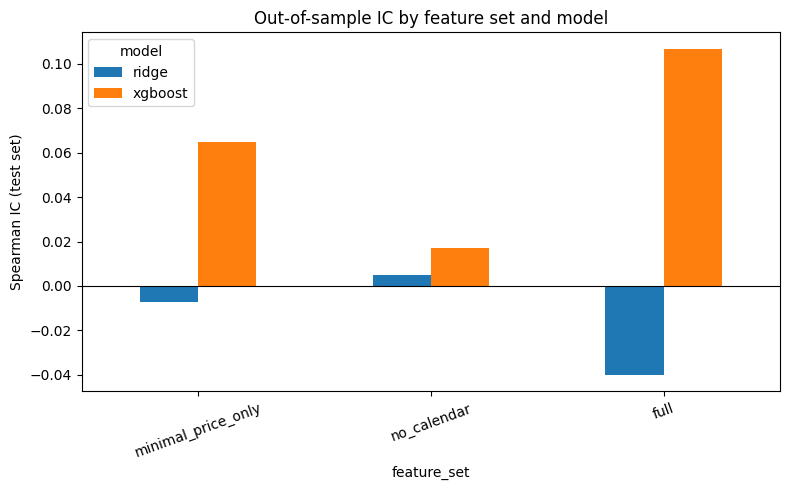

In [8]:
pivot_ic = pd.DataFrame(rows).pivot(index='feature_set', columns='model', values='spearman_ic')
pivot_ic = pivot_ic.loc[list(FEATURE_SETS.keys())]  # keep the order we defined them in

fig, ax = plt.subplots(figsize=(8, 5))
pivot_ic.plot.bar(ax=ax)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Spearman IC (test set)')
ax.set_title('Out-of-sample IC by feature set and model')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

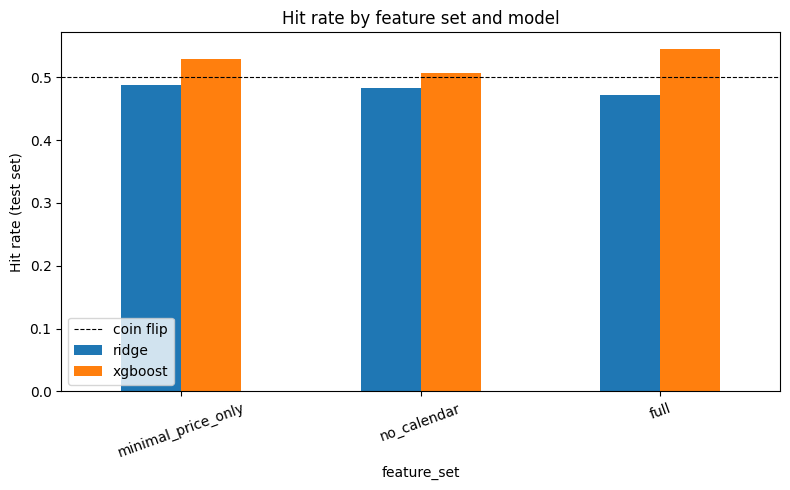

In [9]:
pivot_hit = pd.DataFrame(rows).pivot(index='feature_set', columns='model', values='hit_rate')
pivot_hit = pivot_hit.loc[list(FEATURE_SETS.keys())]

fig, ax = plt.subplots(figsize=(8, 5))
pivot_hit.plot.bar(ax=ax)
ax.axhline(0.5, color='black', linewidth=0.8, linestyle='--', label='coin flip')
ax.set_ylabel('Hit rate (test set)')
ax.set_title('Hit rate by feature set and model')
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()